# Condition comparison: paired analysis across 20 replications

Reads `data/generated/simulation_replications.csv` (20 seeded replications x
5 conditions) and runs paired comparisons across five condition pairs on
three outcome metrics: true-basis utilisation, average cases per session,
and session overrun rate.

## Condition comparison

Defines the shared machinery used throughout the rest of the notebook:
`paired_stats()` (mean, 95% CI, paired t-test, Wilcoxon signed-rank test,
and Cohen's d for a pair of conditions on one metric) and
`plot_comparison()` (the boxplot-with-mean-and-CI figure style used for
every comparison plot below). Runs the five condition-pair comparisons -
baseline vs predicted, predicted vs oracle (the prediction-accuracy
effect), predicted with vs without gap-fill, oracle with vs without
gap-fill, and baseline vs the C4 ceiling - across the five outcome
metrics above, and produces the main `condition_comparisons.png` figure.

### Setup

Imports and working-directory handling, so the notebook runs correctly
whether launched from the project root or from inside `notebooks/`, and
makes sure the `notebooks/figures` output folder exists before anything
tries to save into it.

In [159]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working directory:", os.getcwd())

Path("notebooks/figures").mkdir(parents=True, exist_ok=True)

Working directory: c:\Users\Peter\OneDrive\Desktop\Masters Project


### Data and comparison definitions

Loads the 20-replication x 5-condition summary data, defines the outcome
metrics examined in this section, pivots each into a replication x
condition wide table for paired analysis, and defines the five
condition pairs compared throughout the rest of this notebook.

In [160]:
replications = pd.read_csv("data/generated/simulation_replications.csv")

metrics = [
    ("utilisation_true_pct", "True-basis utilisation (%)"),
    ("avg_cases_per_session", "Avg cases per session"),
    ("overrun_rate_pct", "Session overrun rate (%)"),
    ("mean_overrun_minutes_all", "Mean overrun minutes (all sessions)"),
    ("mean_overrun_minutes_when_overrun", "Mean overrun minutes (when overrun occurs)"),
]

wide = {
    metric: replications.pivot(index="seed", columns="condition", values=metric)
    for metric, _ in metrics
}

comparisons = [
    ("C0: Traditional", "C1: Predicted, no gap-fill", "Baseline vs predicted"),
    ("C1: Predicted, no gap-fill", "C3: Oracle, no gap-fill", "Predicted vs oracle (prediction-accuracy effect)"),
    ("C1: Predicted, no gap-fill", "C2: Predicted, gap-fill", "Predicted: gap-fill effect"),
    ("C3: Oracle, no gap-fill", "C4: Oracle, gap-fill", "Oracle: gap-fill effect"),
    ("C0: Traditional", "C4: Oracle, gap-fill", "Baseline vs best case (ceiling)"),
]

### Paired comparison statistics

Defines `paired_stats()`: for a given pair of conditions and metric,
computes each condition's mean and 95% CI, the paired mean difference
and its own 95% CI, a paired t-test and Wilcoxon signed-rank test for
significance, and Cohen's d for effect size. Used by every paired
comparison in this notebook, not just this section.

In [161]:
def paired_stats(wide_metric_df, cond_a, cond_b):
    a = wide_metric_df[cond_a].values
    b = wide_metric_df[cond_b].values
    n = len(a)

    mean_a, mean_b = a.mean(), b.mean()
    ci_a = stats.t.interval(0.95, n - 1, loc=mean_a, scale=stats.sem(a)) if a.std(ddof=1) > 0 else (mean_a, mean_a)
    ci_b = stats.t.interval(0.95, n - 1, loc=mean_b, scale=stats.sem(b)) if b.std(ddof=1) > 0 else (mean_b, mean_b)

    diff = b - a
    mean_diff = diff.mean()
    diff_sd = diff.std(ddof=1)

    if diff_sd > 0:
        diff_ci = stats.t.interval(0.95, n - 1, loc=mean_diff, scale=stats.sem(diff))
        t_stat, t_p = stats.ttest_rel(b, a)
        try:
            _, w_p = stats.wilcoxon(b, a)
        except ValueError:
            w_p = np.nan
        cohens_d = mean_diff / diff_sd
    else:
        diff_ci = (mean_diff, mean_diff)
        t_stat, t_p, w_p, cohens_d = np.nan, np.nan, np.nan, np.nan

    return {
        "mean_a": mean_a, "ci_a_low": ci_a[0], "ci_a_high": ci_a[1],
        "mean_b": mean_b, "ci_b_low": ci_b[0], "ci_b_high": ci_b[1],
        "mean_diff": mean_diff, "diff_ci_low": diff_ci[0], "diff_ci_high": diff_ci[1],
        "t_stat": t_stat, "t_pvalue": t_p, "wilcoxon_pvalue": w_p,
        "cohens_d": cohens_d, "n": n,
    }

def format_results_table(results_df):
    """
    Returns a display-only copy of a paired-comparison results table
    (results_df, period_results_df, or rtt_results_df), simplified for
    quick reading: drops the individual confidence-interval bound
    columns, rounds the mean/difference/effect-size columns to 3
    decimal places, and shows both p-value columns as "< 0.05" for
    anything below the conventional significance threshold rather than
    the exact attained value - these tables are for scanning which
    comparisons are significant, not for citing an exact p-value. Does
    not alter the original dataframe or the full-precision CSV already
    saved to disk.
    """
    def format_p(p):
        if pd.isna(p):
            return "n/a"
        if p < 0.05:
            return "< 0.05"
        return f"{p:.3f}"

    drop_cols = ["ci_a_low", "ci_a_high", "ci_b_low", "ci_b_high", "diff_ci_low", "diff_ci_high"]
    display_df = results_df.drop(columns=[c for c in drop_cols if c in results_df.columns]).copy()

    for col in ["mean_a", "mean_b", "mean_diff", "cohens_d"]:
        if col in display_df.columns:
            display_df[col] = display_df[col].round(3)

    display_df["t_pvalue"] = display_df["t_pvalue"].apply(format_p)
    display_df["wilcoxon_pvalue"] = display_df["wilcoxon_pvalue"].apply(format_p)

    return display_df

### Comparison plot style

Defines `plot_comparison()`: the shared boxplot-with-mean-and-95%-CI
figure style used for every paired comparison chart in this notebook.

In [162]:
def format_p_value(p_value):
    """
    Formats a p-value for direct display on a chart panel: "p < 0.001"
    for very small values, otherwise "p = X.XXX" to three decimal
    places. Returns "p = n/a" for a missing/undefined p-value (e.g. a
    comparison with zero variance in the paired differences).
    """
    if pd.isna(p_value):
        return "p = n/a"
    if p_value < 0.001:
        return "p < 0.001"
    return f"p = {p_value:.3f}"


def plot_comparison(ax, wide_metric_df, cond_a, cond_b, metric_label, p_value=None):
    """
    Draws one paired-comparison panel: a boxplot of the two conditions'
    raw values side by side, overlaid with the mean and 95% CI for each
    (red dashed line/error bars). If p_value is given, annotates the
    panel with the formatted p-value itself (see format_p_value()) in
    the top-right corner, inside the axes rather than above them, so it
    never competes for space with the panel's own title. Driven by the
    paired t-test p-value throughout this notebook - the data
    distributions here are reasonably close to normal, so the t-test is
    treated as primary, with the Wilcoxon signed-rank test still
    reported alongside it in the results tables as a robustness check
    rather than shown on the chart itself.
    """
    a = wide_metric_df[cond_a].values
    b = wide_metric_df[cond_b].values
    n = len(a)

    label_a = cond_a.split(":")[0]
    label_b = cond_b.split(":")[0]

    ax.boxplot([a, b], positions=[0, 1], widths=0.5, tick_labels=[label_a, label_b])

    mean_a, mean_b = a.mean(), b.mean()
    sem_a, sem_b = stats.sem(a), stats.sem(b)
    ci_a = stats.t.interval(0.95, n - 1, loc=mean_a, scale=sem_a) if a.std(ddof=1) > 0 else (mean_a, mean_a)
    ci_b = stats.t.interval(0.95, n - 1, loc=mean_b, scale=sem_b) if b.std(ddof=1) > 0 else (mean_b, mean_b)
    err_a, err_b = mean_a - ci_a[0], mean_b - ci_b[0]

    ax.plot([0, 1], [mean_a, mean_b], color="red", linestyle="--", linewidth=1, zorder=4)
    ax.errorbar([0, 1], [mean_a, mean_b], yerr=[[err_a, err_b], [err_a, err_b]],
                fmt="o", color="red", capsize=5, zorder=5, label="Mean (95% CI)")

    ax.set_ylabel(metric_label)
    ax.legend(fontsize=8, loc="upper left")

    if p_value is not None:
        ax.text(0.98, 0.97, format_p_value(p_value), transform=ax.transAxes,
                 ha="right", va="top", fontsize=9,
                 bbox=dict(boxstyle="round", facecolor="white", alpha=0.7, edgecolor="none"))

### Headline comparison figure

Runs `paired_stats()` across all five comparisons and outcome metrics,
builds the main `condition_comparisons.png` figure via
`plot_comparison()`, and saves the full results table to
`comparison_results.csv`.

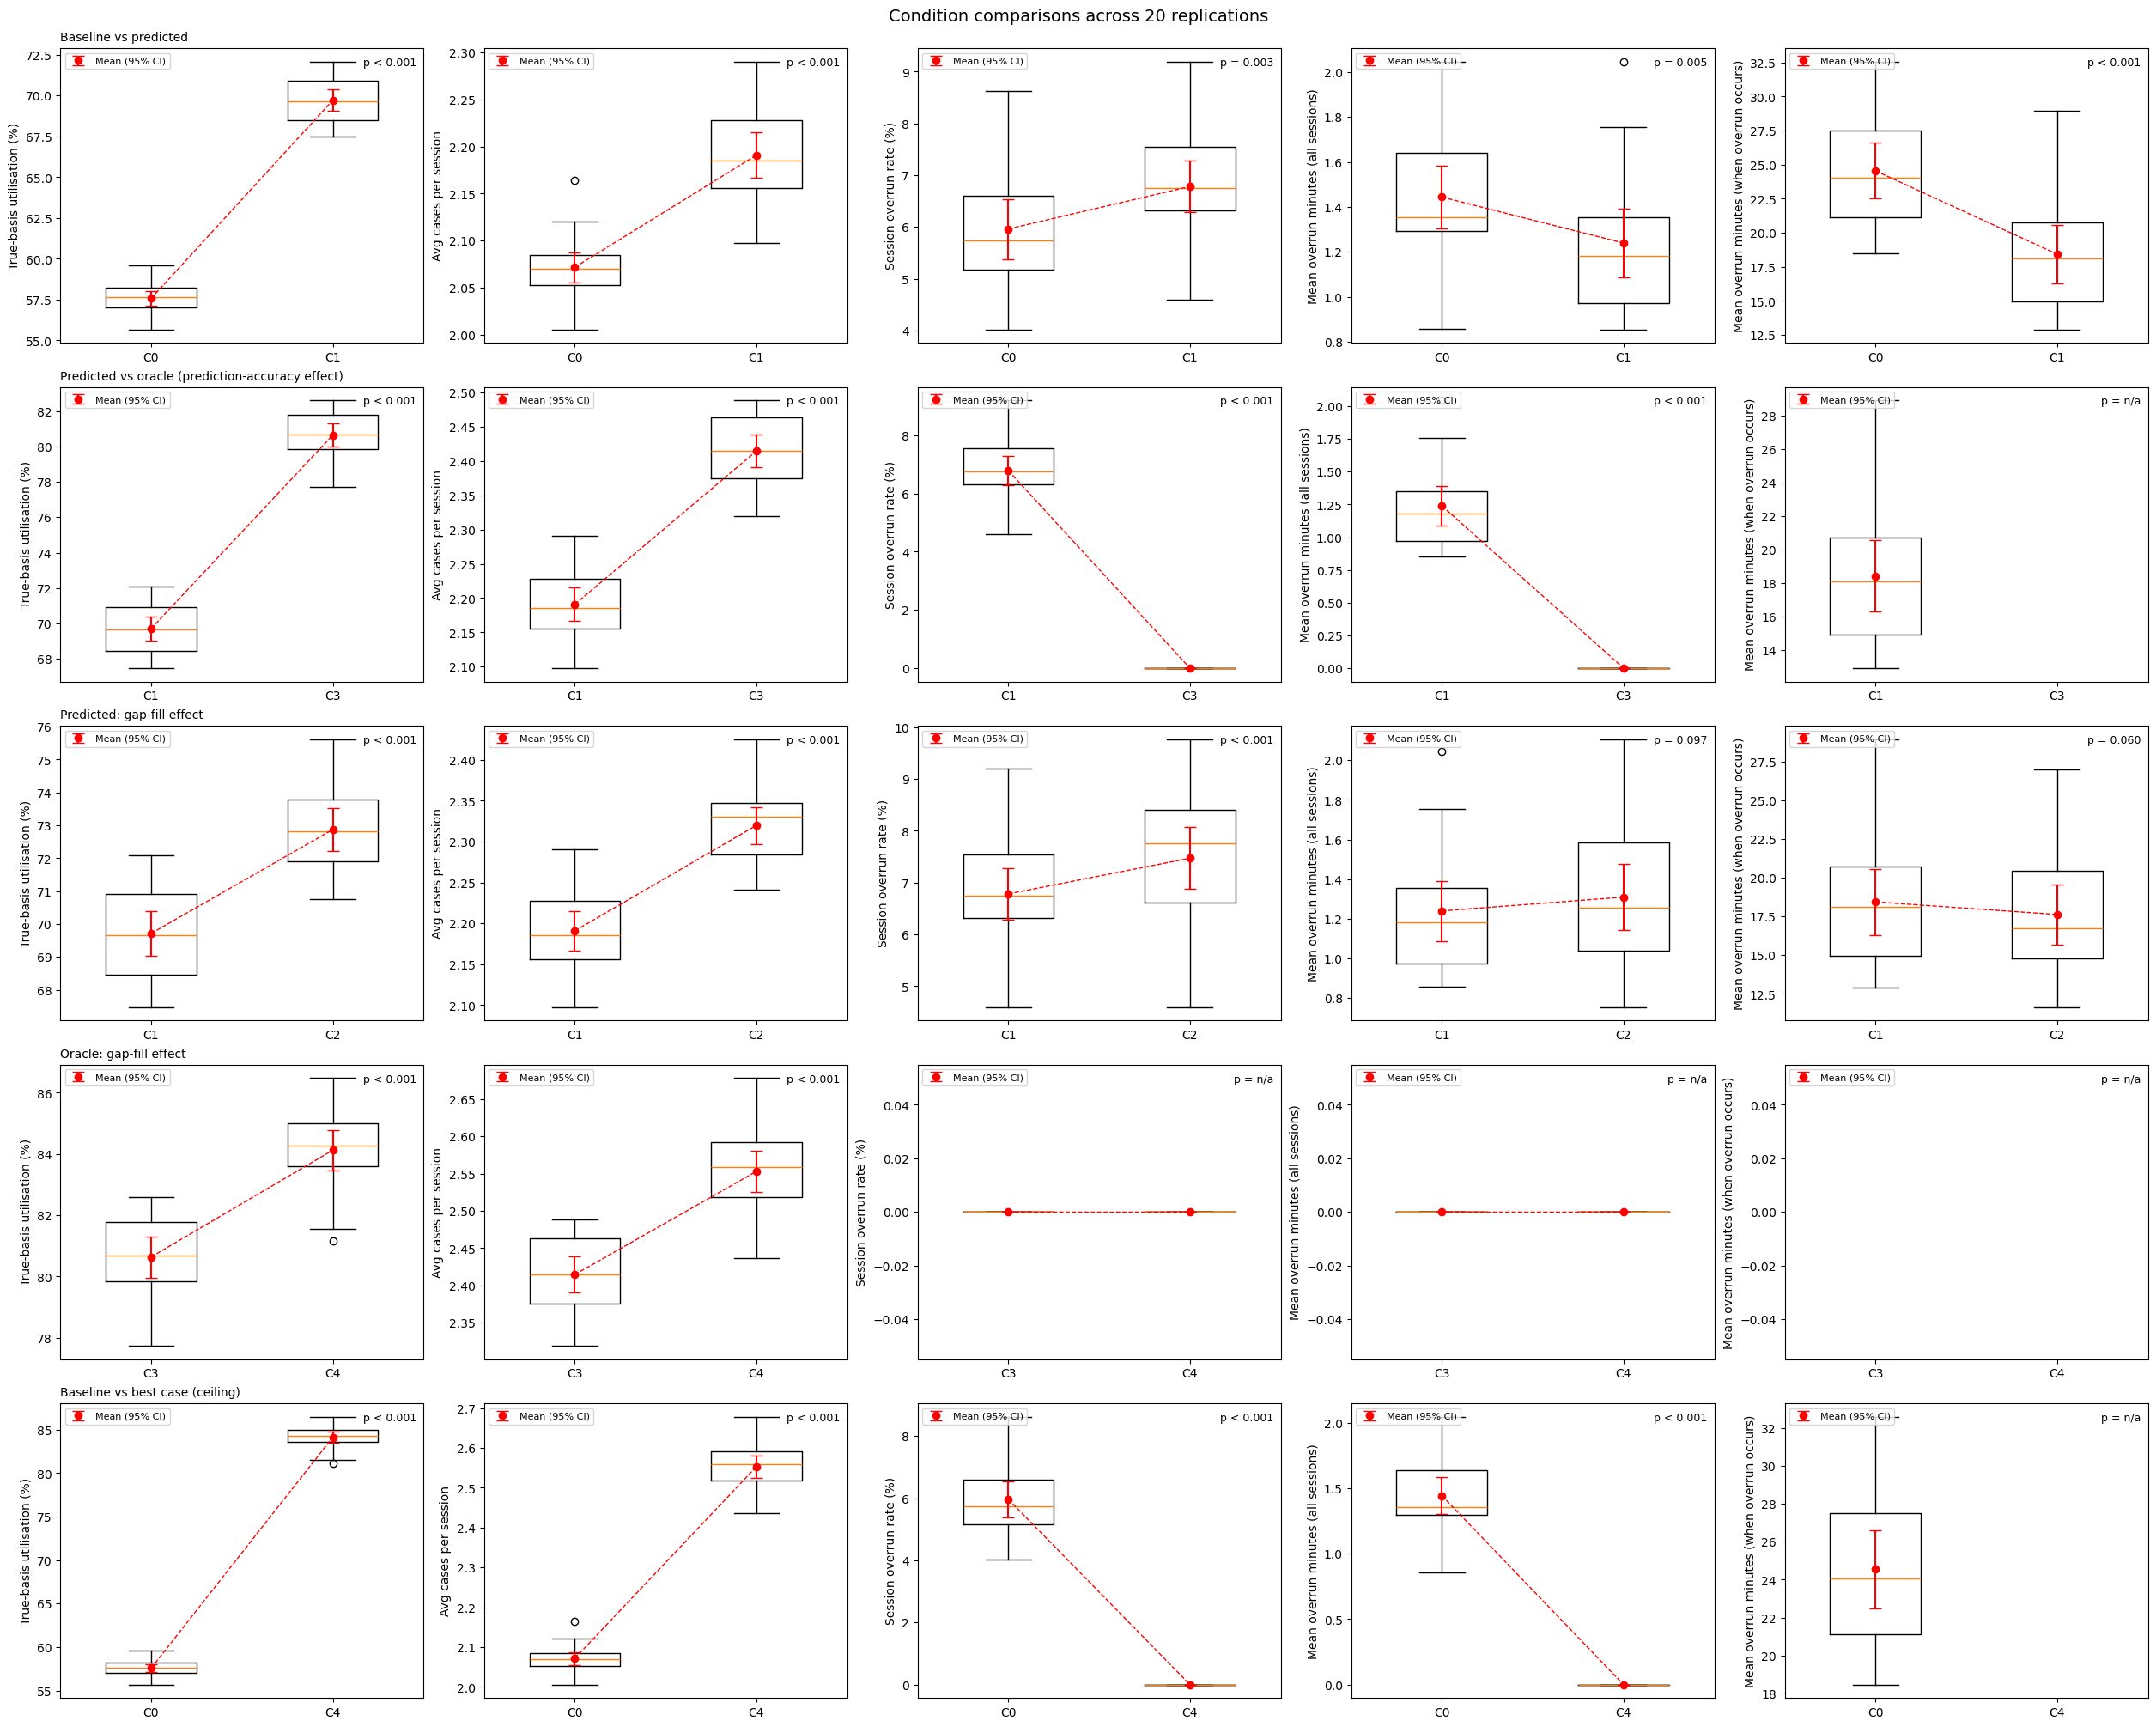

,comparison,metric,condition_a,condition_b,mean_a,mean_b,mean_diff,t_stat,t_pvalue,wilcoxon_pvalue,cohens_d,n
0,Baseline vs predicted,utilisation_true_pct,C0: Traditional,"C1: Predicted, no gap-fill",57.577,69.715,12.138,41.911223,< 0.05,< 0.05,9.372,20
1,Baseline vs predicted,avg_cases_per_session,C0: Traditional,"C1: Predicted, no gap-fill",2.072,2.191,0.119,14.991566,< 0.05,< 0.05,3.352,20
2,Baseline vs predicted,overrun_rate_pct,C0: Traditional,"C1: Predicted, no gap-fill",5.963,6.782,0.819,3.455130,< 0.05,< 0.05,0.773,20
3,Baseline vs predicted,mean_overrun_minutes_all,C0: Traditional,"C1: Predicted, no gap-fill",1.444,1.239,-0.205,-3.207114,< 0.05,< 0.05,-0.717,20
4,Baseline vs predicted,mean_overrun_minutes_when_overrun,C0: Traditional,"C1: Predicted, no gap-fill",24.552,18.432,-6.120,-5.202404,< 0.05,< 0.05,-1.163,20
5,Predicted vs oracle (prediction-accuracy effect),utilisation_true_pct,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",69.715,80.637,10.923,58.766818,< 0.05,< 0.05,13.141,20
6,Predicted vs oracle (prediction-accuracy effect),avg_cases_per_session,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",2.191,2.415,0.224,42.113475,< 0.05,< 0.05,9.417,20
7,Predicted vs oracle (prediction-accuracy effect),overrun_rate_pct,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",6.782,0.000,-6.782,-28.487216,< 0.05,< 0.05,-6.370,20
8,Predicted vs oracle (prediction-accuracy effect),mean_overrun_minutes_all,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",1.239,0.000,-1.239,-17.073502,< 0.05,< 0.05,-3.818,20
9,Predicted vs oracle (prediction-accuracy effect),mean_overrun_minutes_when_overrun,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",18.432,NaN,NaN,NaN,n/a,n/a,NaN,20


In [163]:
fig, axes = plt.subplots(len(comparisons), len(metrics),
                          figsize=(5 * len(metrics), 4 * len(comparisons)),
                          constrained_layout=True)

results_rows = []

for i, (cond_a, cond_b, comp_label) in enumerate(comparisons):
    for j, (metric, metric_label) in enumerate(metrics):
        wdf = wide[metric]
        row = paired_stats(wdf, cond_a, cond_b)
        results_rows.append({
            "comparison": comp_label,
            "metric": metric,
            "condition_a": cond_a,
            "condition_b": cond_b,
            **row,
        })

        ax = axes[i, j]
        plot_comparison(ax, wdf, cond_a, cond_b, metric_label, p_value=row["t_pvalue"])
        if j == 0:
            ax.set_title(comp_label, fontsize=10, loc="left")

fig.suptitle("Condition comparisons across 20 replications", fontsize=14)
fig.savefig("notebooks/figures/condition_comparisons.png", dpi=150, bbox_inches="tight")
plt.show()

results_df = pd.DataFrame(results_rows)
results_df.to_csv("data/generated/comparison_results.csv", index=False)
format_results_table(results_df)

## Overrun rate by session period

Checks whether gap-fill's effect on overrun rate (seen in the main
condition comparison) concentrates in particular session types. Reports
the full table across all five comparisons and four periods, but only
plots C1 vs C2, since C3/C4 are structurally flat at zero overrun in
every period (oracle-based booking can't overrun by construction).

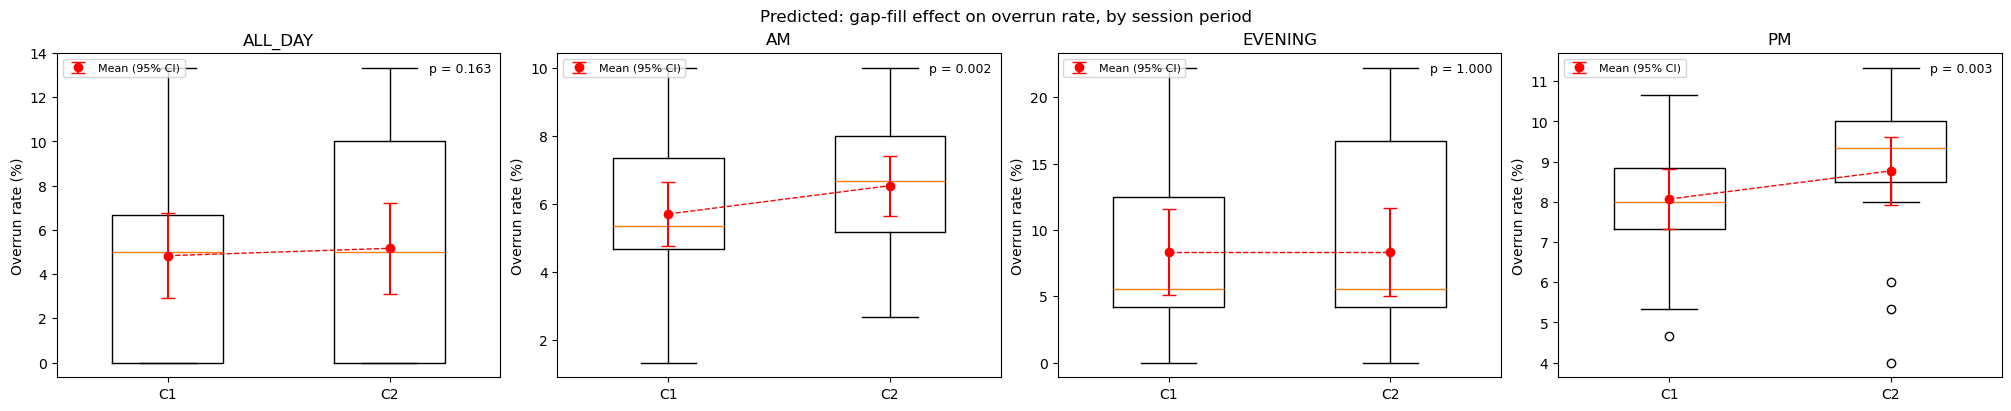

,period,comparison,mean_a,mean_b,mean_diff,t_stat,t_pvalue,wilcoxon_pvalue,cohens_d,n
0,ALL_DAY,Baseline vs predicted,2.000,4.833,2.833,2.740735e+00,< 0.05,< 0.05,0.613,20
1,ALL_DAY,Predicted vs oracle (prediction-accuracy effect),4.833,0.000,-4.833,-5.253340e+00,< 0.05,< 0.05,-1.175,20
2,ALL_DAY,Predicted: gap-fill effect,4.833,5.167,0.333,1.452966e+00,0.163,0.157,0.325,20
3,ALL_DAY,Oracle: gap-fill effect,0.000,0.000,0.000,NaN,n/a,n/a,NaN,20
4,ALL_DAY,Baseline vs best case (ceiling),2.000,0.000,-2.000,-3.942772e+00,< 0.05,< 0.05,-0.882,20
5,AM,Baseline vs predicted,5.633,5.700,0.067,1.269463e-01,0.900,0.683,0.028,20
6,AM,Predicted vs oracle (prediction-accuracy effect),5.700,0.000,-5.700,-1.252947e+01,< 0.05,< 0.05,-2.802,20
7,AM,Predicted: gap-fill effect,5.700,6.533,0.833,3.526266e+00,< 0.05,< 0.05,0.788,20
8,AM,Oracle: gap-fill effect,0.000,0.000,0.000,NaN,n/a,n/a,NaN,20
9,AM,Baseline vs best case (ceiling),5.633,0.000,-5.633,-1.139534e+01,< 0.05,< 0.05,-2.548,20


In [164]:
by_period = pd.read_csv("data/generated/simulation_replications_by_period.csv")
periods = sorted(by_period["period"].unique())

period_results_rows = []
for period in periods:
    period_df = by_period[by_period["period"] == period]
    period_wide = period_df.pivot(index="seed", columns="condition", values="overrun_rate_pct")
    for cond_a, cond_b, comp_label in comparisons:
        row = paired_stats(period_wide, cond_a, cond_b)
        period_results_rows.append({"period": period, "comparison": comp_label, **row})

period_results_df = pd.DataFrame(period_results_rows)
period_results_df.to_csv("data/generated/comparison_results_by_period.csv", index=False)

fig, axes = plt.subplots(1, len(periods), figsize=(5 * len(periods), 4), constrained_layout=True)
for ax, period in zip(axes, periods):
    period_df = by_period[by_period["period"] == period]
    period_wide = period_df.pivot(index="seed", columns="condition", values="overrun_rate_pct")
    row = paired_stats(period_wide, "C1: Predicted, no gap-fill", "C2: Predicted, gap-fill")
    plot_comparison(ax, period_wide, "C1: Predicted, no gap-fill", "C2: Predicted, gap-fill", "Overrun rate (%)", p_value=row["t_pvalue"])
    ax.set_title(period)
fig.suptitle("Predicted: gap-fill effect on overrun rate, by session period")
fig.savefig("notebooks/figures/overrun_by_period.png", dpi=150, bbox_inches="tight")
plt.show()

format_results_table(period_results_df)

## Two-part regression: what predicts overrun

Restricted to C0/C1/C2 - C3/C4 are excluded because they have zero
overruns by construction, which would cause complete separation in the
logistic model below. Part one: does a session overrun at all (logistic
regression on patients_booked and condition). Part two, further down:
given that it does overrun, how severe is it (linear regression,
restricted to sessions where overrun occurred).

In [ ]:
import numpy as np
import statsmodels.formula.api as smf

session_level = pd.read_csv("data/generated/simulation_session_level.csv")
session_level["overrun"] = session_level["overrun"].astype(int)

logit_model = smf.logit("overrun ~ patients_booked + C(condition)", data=session_level).fit()
print(logit_model.summary())
print(f"\nMcFadden's pseudo R-squared: {logit_model.prsquared:.4f}")
print("\nOdds ratios:")
print(np.exp(logit_model.params))

Optimization terminated successfully.
         Current function value: 0.242603
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                overrun   No. Observations:                20880
Model:                          Logit   Df Residuals:                    20876
Method:                           MLE   Df Model:                            3
Date:                Thu, 08 Oct 2026   Pseudo R-squ.:                 0.01709
Time:                        10:09:51   Log-Likelihood:                -5065.6
converged:                       True   LL-Null:                       -5153.6
Covariance Type:            nonrobust   LLR p-value:                 5.911e-38
                                                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------
Intercept                                   

### Severity model

Conditional on a session actually overrunning, models how many minutes
over it runs, using the same predictors as the logistic model above.

In [ ]:
overrun_only = session_level[session_level["overrun"] == 1]

severity_model = smf.ols("overrun_minutes ~ patients_booked + C(condition)", data=overrun_only).fit()
print(severity_model.summary())
print(f"\nR-squared: {severity_model.rsquared:.4f}")
print(f"Adjusted R-squared: {severity_model.rsquared_adj:.4f}")

                            OLS Regression Results                            
Dep. Variable:        overrun_minutes   R-squared:                       0.031
Model:                            OLS   Adj. R-squared:                  0.029
Method:                 Least Squares   F-statistic:                     15.14
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           1.07e-09
Time:                        10:09:51   Log-Likelihood:                -6049.9
No. Observations:                1407   AIC:                         1.211e+04
Df Residuals:                    1403   BIC:                         1.213e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

## Prediction calibration

Checks the duration predictor's own accuracy directly - separate from
its downstream effect on the simulation results above - using the full
patient population (booked or not) across the same 20 seeds. Reports
coverage (should be ~75%, since the predictor targets the 75th
percentile) and percentage accuracy, broken down by predicted-duration
quintile, size category, and backoff level, to check the predictor is
consistently calibrated rather than just correct on average.

In [167]:
calibration = pd.read_csv("data/generated/prediction_calibration.csv")

# Raw mean absolute error in minutes, alongside the existing percentage-based
# accuracy metrics - the proposal names MAE specifically as the prediction-
# accuracy success metric, so this reports it directly rather than only the
# percentage-difference figures.
calibration["abs_error_min"] = (calibration["predicted_p75_min"] - calibration["true_duration_min"]).abs()

def calibration_summary(df):
    return pd.Series({
        "n": len(df),
        "coverage_pct": 100 * df["covered"].mean(),
        "mean_pct_diff": df["pct_diff"].mean(),
        "mean_abs_pct_diff": df["abs_pct_diff"].mean(),
        "mean_abs_error_min": df["abs_error_min"].mean(),
    })

print("Overall calibration:")
print(calibration_summary(calibration))

calibration["predicted_quintile"] = pd.qcut(
    calibration["predicted_p75_min"], 5,
    labels=["Q1 (shortest predicted)", "Q2", "Q3", "Q4", "Q5 (longest predicted)"]
)

print("\nBy predicted-duration quintile (grouped by an input, not the outcome):")
print(calibration.groupby("predicted_quintile", observed=True).apply(calibration_summary, include_groups=False))

print("\nBy size category:")
print(calibration.groupby("size_category").apply(calibration_summary, include_groups=False))

print("\nBy backoff level:")
print(calibration.groupby("backoff_level").apply(calibration_summary, include_groups=False))

Overall calibration:
n                     29207.000000
coverage_pct             73.903516
mean_pct_diff            20.709075
mean_abs_pct_diff        27.666178
mean_abs_error_min       17.989489
dtype: float64

By predicted-duration quintile (grouped by an input, not the outcome):
                              n  coverage_pct  mean_pct_diff  \
predicted_quintile                                             
Q1 (shortest predicted)  6335.0     76.274665      24.869089   
Q2                       6296.0     72.649301      20.487710   
Q3                       5106.0     71.856639      18.733600   
Q4                       6573.0     72.736954      18.033270   
Q5 (longest predicted)   4897.0     76.148662      21.263470   

                         mean_abs_pct_diff  mean_abs_error_min  
predicted_quintile                                              
Q1 (shortest predicted)          31.696250            4.905730  
Q2                               27.967855           13.812278  
Q3      

### Calibration plots

Plots a 3,000-row sample of the full calibration set (for readability -
the summary statistics above already use the full dataset): predicted
vs true duration against a perfect-match line, annotated with overall
coverage against the 75% target, and prediction error (% difference)
against true duration, to check whether error grows or shrinks with
case length.

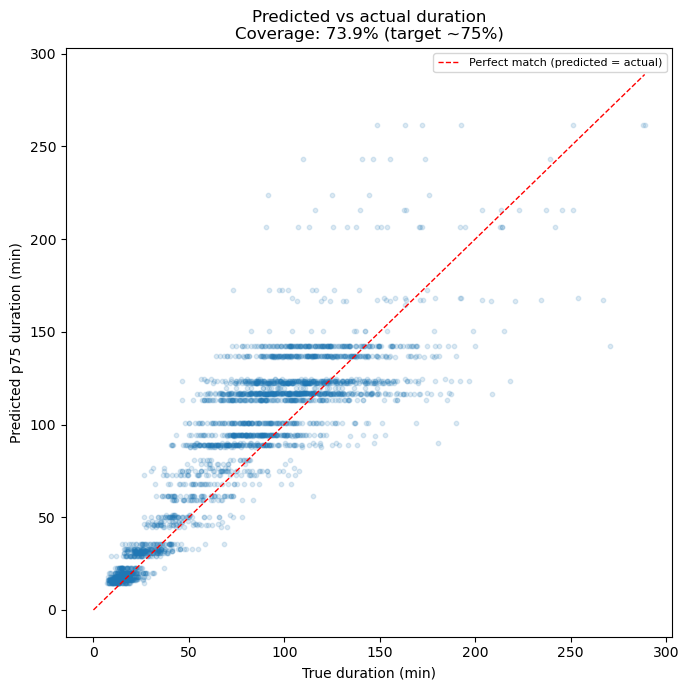

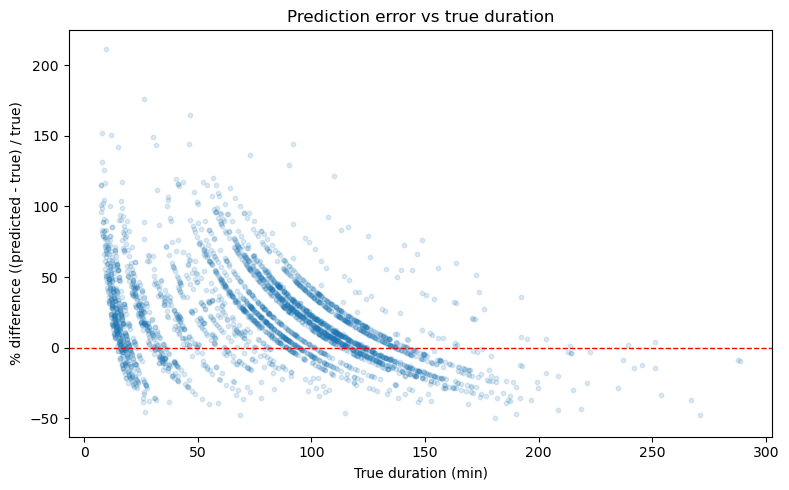

In [168]:
sample = calibration.sample(min(3000, len(calibration)), random_state=1)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(sample["true_duration_min"], sample["predicted_p75_min"], alpha=0.15, s=10)
lims = [0, max(sample["true_duration_min"].max(), sample["predicted_p75_min"].max())]
ax.plot(lims, lims, color="red", linestyle="--", linewidth=1, label="Perfect match (predicted = actual)")
ax.set_xlabel("True duration (min)")
ax.set_ylabel("Predicted p75 duration (min)")
overall_coverage = calibration_summary(calibration)["coverage_pct"]
ax.set_title(f"Predicted vs actual duration\nCoverage: {overall_coverage:.1f}% (target ~75%)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("notebooks/figures/calibration_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample["true_duration_min"], sample["pct_diff"], alpha=0.15, s=10)
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("True duration (min)")
ax.set_ylabel("% difference ((predicted - true) / true)")
ax.set_title("Prediction error vs true duration")
fig.tight_layout()
fig.savefig("notebooks/figures/calibration_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

## 18-week RTT compliance

Checks whether the utilisation gains seen above translate into more patients
actually being treated within the NHS 18-week RTT target, using the
26-week-horizon replications (see run_rtt_replications() and the
corresponding decision log entry - a longer horizon than the 12-week
analysis above, since referrals need a full 18 weeks to reach a verdict).
Reported separately for two cohorts, using the same paired_stats()/
plot_comparison() machinery as the condition comparisons above: the initial
375-patient backlog (capped at a 60.8% achievable ceiling, since 39.2% were
already breached at snapshot), and new arrivals referred early enough to
have had the full 18 weeks play out (later arrivals are right-censored and
excluded).

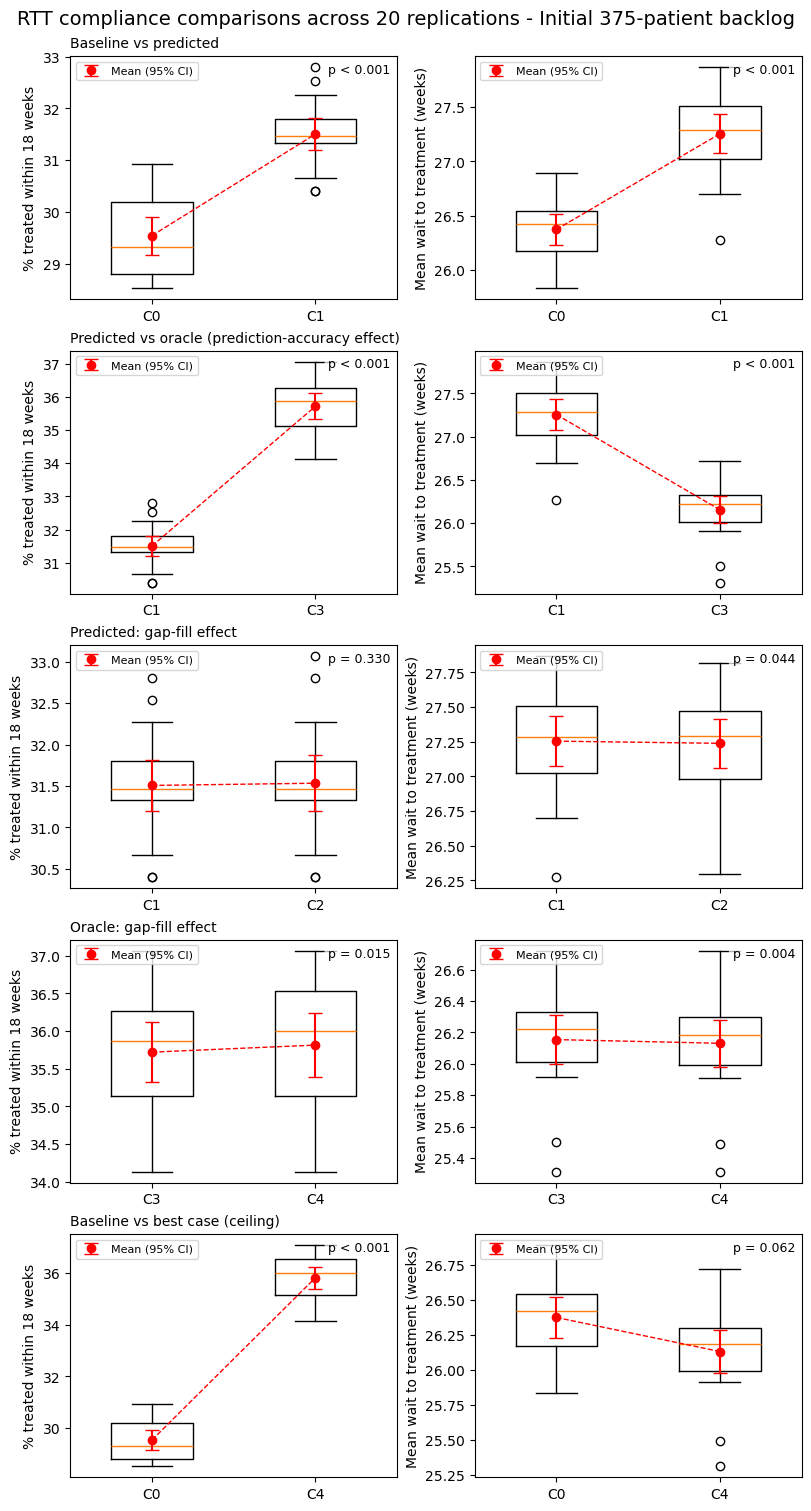

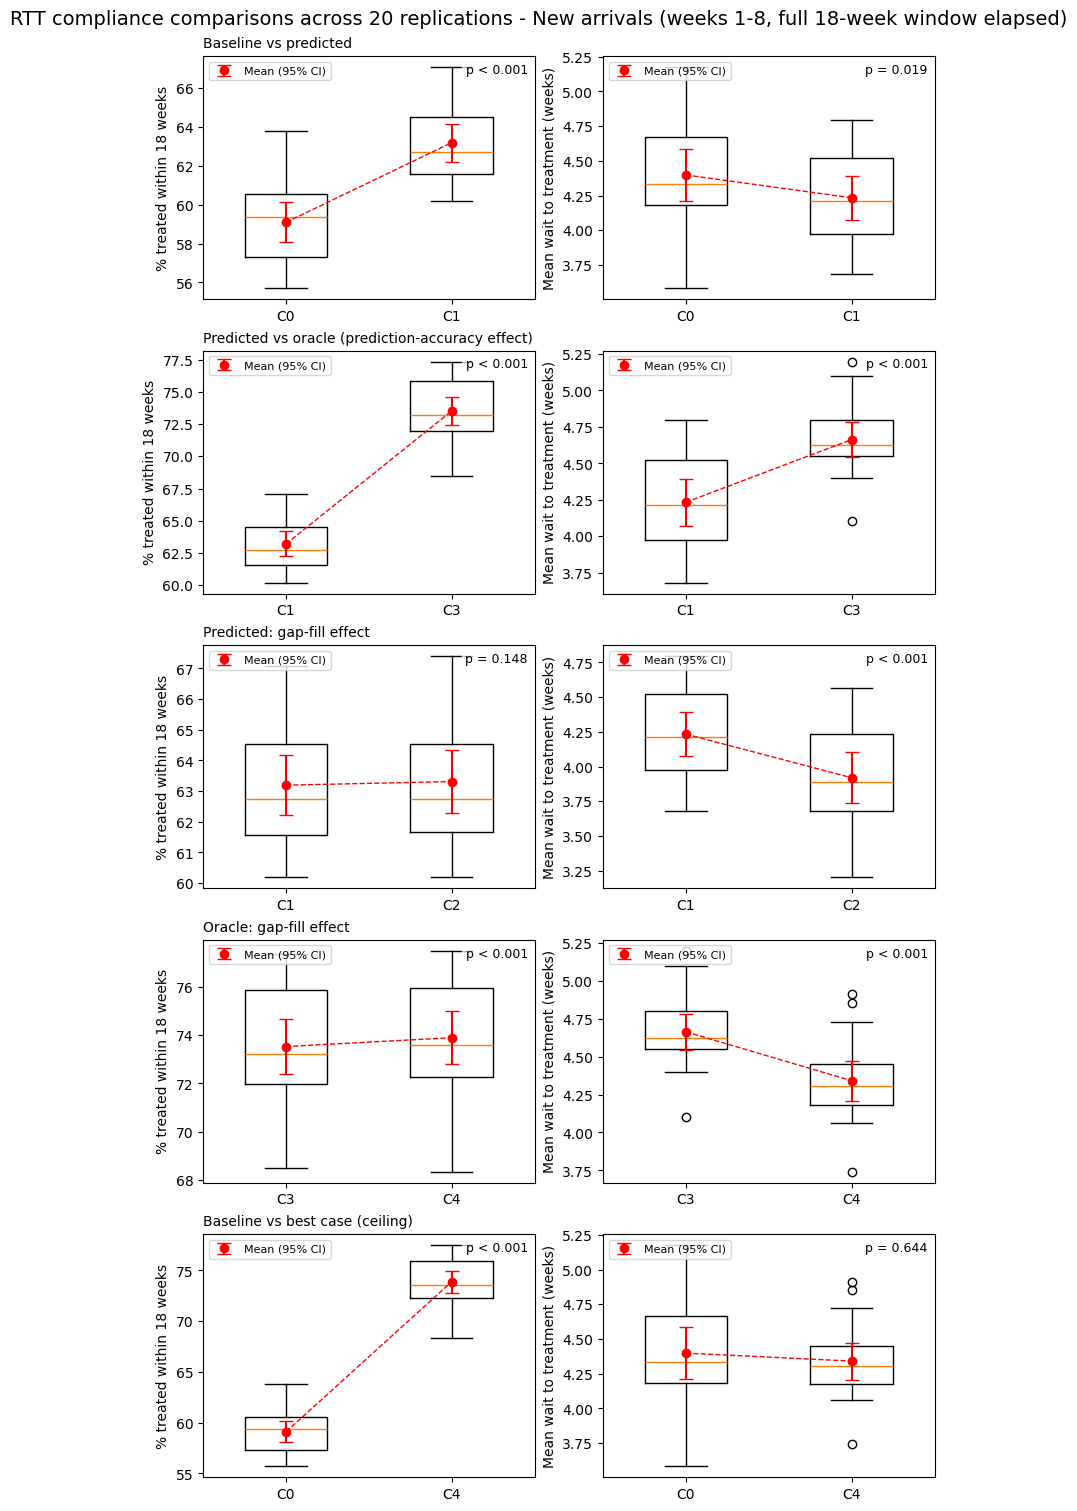

,cohort,comparison,metric,condition_a,condition_b,mean_a,mean_b,mean_diff,t_stat,t_pvalue,wilcoxon_pvalue,cohens_d,n
0,initial,Baseline vs predicted,pct_within_target,C0: Traditional,"C1: Predicted, no gap-fill",29.547,31.507,1.960,15.769597,< 0.05,< 0.05,3.526,20
1,initial,Baseline vs predicted,mean_wait_weeks_at_treatment,C0: Traditional,"C1: Predicted, no gap-fill",26.374,27.254,0.880,9.512352,< 0.05,< 0.05,2.127,20
2,initial,Predicted vs oracle (prediction-accuracy effect),pct_within_target,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",31.507,35.720,4.213,21.397055,< 0.05,< 0.05,4.785,20
3,initial,Predicted vs oracle (prediction-accuracy effect),mean_wait_weeks_at_treatment,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",27.254,26.155,-1.100,-11.920460,< 0.05,< 0.05,-2.665,20
4,initial,Predicted: gap-fill effect,pct_within_target,"C1: Predicted, no gap-fill","C2: Predicted, gap-fill",31.507,31.533,0.027,1.000000,0.330,0.317,0.224,20
5,initial,Predicted: gap-fill effect,mean_wait_weeks_at_treatment,"C1: Predicted, no gap-fill","C2: Predicted, gap-fill",27.254,27.239,-0.016,-2.162410,< 0.05,0.055,-0.484,20
6,initial,Oracle: gap-fill effect,pct_within_target,"C3: Oracle, no gap-fill","C4: Oracle, gap-fill",35.720,35.813,0.093,2.665871,< 0.05,< 0.05,0.596,20
7,initial,Oracle: gap-fill effect,mean_wait_weeks_at_treatment,"C3: Oracle, no gap-fill","C4: Oracle, gap-fill",26.155,26.131,-0.023,-3.269514,< 0.05,< 0.05,-0.731,20
8,initial,Baseline vs best case (ceiling),pct_within_target,C0: Traditional,"C4: Oracle, gap-fill",29.547,35.813,6.267,27.524521,< 0.05,< 0.05,6.155,20
9,initial,Baseline vs best case (ceiling),mean_wait_weeks_at_treatment,C0: Traditional,"C4: Oracle, gap-fill",26.374,26.131,-0.243,-1.979527,0.062,< 0.05,-0.443,20


In [169]:
rtt = pd.read_csv("data/generated/simulation_rtt_replications.csv")

rtt_metrics = [
    ("pct_within_target", "% treated within 18 weeks"),
    ("mean_wait_weeks_at_treatment", "Mean wait to treatment (weeks)"),
]

rtt_results_rows = []

for cohort, cohort_label in [("initial", "Initial 375-patient backlog"),
                              ("new_arrivals_eligible", "New arrivals (weeks 1-8, full 18-week window elapsed)")]:
    cohort_df = rtt[rtt["cohort"] == cohort]
    wide_rtt = {
        metric: cohort_df.pivot(index="seed", columns="condition", values=metric)
        for metric, _ in rtt_metrics
    }

    fig, axes = plt.subplots(len(comparisons), len(rtt_metrics),
                              figsize=(4 * len(rtt_metrics), 3 * len(comparisons)),
                              constrained_layout=True)

    for i, (cond_a, cond_b, comp_label) in enumerate(comparisons):
        for j, (metric, metric_label) in enumerate(rtt_metrics):
            wdf = wide_rtt[metric]
            row = paired_stats(wdf, cond_a, cond_b)
            rtt_results_rows.append({
                "cohort": cohort,
                "comparison": comp_label,
                "metric": metric,
                "condition_a": cond_a,
                "condition_b": cond_b,
                **row,
            })

            ax = axes[i, j]
            plot_comparison(ax, wdf, cond_a, cond_b, metric_label, p_value=row["t_pvalue"])
            if j == 0:
                ax.set_title(comp_label, fontsize=10, loc="left")

    fig.suptitle(f"RTT compliance comparisons across 20 replications - {cohort_label}", fontsize=14)
    fig.savefig(f"notebooks/figures/rtt_comparisons_{cohort}.png", dpi=150, bbox_inches="tight")
    plt.show()

rtt_results_df = pd.DataFrame(rtt_results_rows)
rtt_results_df.to_csv("data/generated/rtt_comparison_results.csv", index=False)
format_results_table(rtt_results_df)

## Priority-order overrides from size-fit skipping

Quantifies how much the first-fit skip mechanism (see the RTT-compliance
decision log entry) reorders booking relative to strict priority order,
using build_booking_order_diagnostic(). For every booked patient, records
their position in their surgeon's priority-ordered queue at the moment of
booking - position 0 means booked immediately; a higher position means
that many more urgent or longer-waiting patients, whose procedures didn't
fit the session's remaining capacity, were skipped over.

Queue position at booking, by procedure size category:
               mean  50%    max   count
size_category                          
Large           0.4  0.0    3.0   141.0
Medium          0.9  1.0    8.0  1718.0
Small          20.2  3.0  224.0  1298.0

Queue position at booking, by priority category:
                   mean  50%    max   count
priority_category                          
P2                  0.7  0.0   10.0   751.0
P3                  4.5  1.0   77.0  1294.0
P4                 19.4  2.0  224.0  1112.0

New arrivals booked at queue position 0 (i.e., immediately): 30.7%
New arrivals: mean queue position at booking: 10.1, median: 1


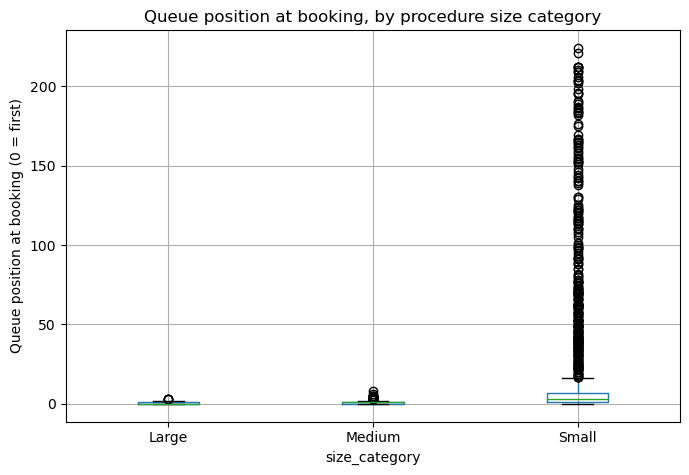

In [170]:
booking_order = pd.read_csv("data/generated/booking_order_diagnostic.csv")

print("Queue position at booking, by procedure size category:")
print(booking_order.groupby("size_category")["queue_index"].describe()[["mean", "50%", "max", "count"]].round(1))
print()
print("Queue position at booking, by priority category:")
print(booking_order.groupby("priority_category")["queue_index"].describe()[["mean", "50%", "max", "count"]].round(1))
print()

new_arrivals_diag = booking_order[booking_order["arrival_week"] > 0]
pct_immediate = 100 * (new_arrivals_diag["queue_index"] == 0).mean()
print(f"New arrivals booked at queue position 0 (i.e., immediately): {pct_immediate:.1f}%")
print(f"New arrivals: mean queue position at booking: {new_arrivals_diag['queue_index'].mean():.1f}, "
      f"median: {new_arrivals_diag['queue_index'].median():.0f}")

fig, ax = plt.subplots(figsize=(7, 5))
booking_order.boxplot(column="queue_index", by="size_category", ax=ax)
ax.set_ylabel("Queue position at booking (0 = first)")
ax.set_title("Queue position at booking, by procedure size category")
plt.suptitle("")
fig.tight_layout()
fig.savefig("notebooks/figures/booking_order_by_size.png", dpi=150, bbox_inches="tight")
plt.show()

## Duration prediction: quantile regression forest vs backoff hierarchy

Compares the backoff-hierarchy predictor evaluated above against a quantile
regression forest (Meinshausen, 2006), matching the technique used by Dean
et al. (2022) for the same individualised surgery-duration-prediction
problem. Both methods are evaluated using matched 5-fold cross-validation
on the same 4,000 historical cases (see ml_duration_predictor.py) - every
case is scored by a version of each method that never saw it during
fitting. This is a standalone comparison: it does not feed into the
packing/simulation pipeline evaluated elsewhere in this notebook.

Backoff hierarchy (matched cross-validation):
n                     4000.000000
coverage_pct            74.575000
mean_pct_diff           20.952576
mean_abs_pct_diff       27.794122
mean_abs_error_min      18.162431
dtype: float64

Quantile regression forest (matched cross-validation):
n                     4000.000000
coverage_pct            74.725000
mean_pct_diff           21.102976
mean_abs_pct_diff       27.939123
mean_abs_error_min      18.248337
dtype: float64

Paired comparison of absolute error (ML - backoff): mean diff = 0.09 min
t-test p = 0.1679, Wilcoxon p = 0.1712, Cohen's d = 0.022


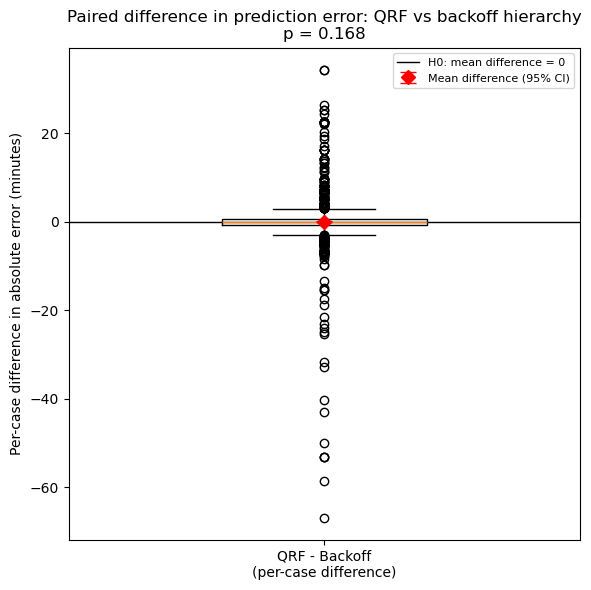

In [ ]:
ml_comparison = pd.read_csv("data/generated/ml_vs_backoff_comparison.csv")

def accuracy_summary(df, pred_col):
    actual = df["actual_duration_min"]
    pred = df[pred_col]
    pct_diff = 100 * (pred - actual) / actual
    return pd.Series({
        "n": len(df),
        "coverage_pct": 100 * (actual <= pred).mean(),
        "mean_pct_diff": pct_diff.mean(),
        "mean_abs_pct_diff": pct_diff.abs().mean(),
        "mean_abs_error_min": (pred - actual).abs().mean(),
    })

print("Backoff hierarchy (matched cross-validation):")
print(accuracy_summary(ml_comparison, "backoff_predicted_p75_min"))
print("\nQuantile regression forest (matched cross-validation):")
print(accuracy_summary(ml_comparison, "ml_predicted_p75_min"))

# Paired comparison on absolute error, same methodology as the condition
# comparisons elsewhere in this notebook - is one method's per-case error
# significantly different from the other's, not just descriptively so.
backoff_abs_error = (ml_comparison["backoff_predicted_p75_min"] - ml_comparison["actual_duration_min"]).abs()
ml_abs_error = (ml_comparison["ml_predicted_p75_min"] - ml_comparison["actual_duration_min"]).abs()
diff = ml_abs_error - backoff_abs_error

t_stat, t_p = stats.ttest_rel(ml_abs_error, backoff_abs_error)
w_stat, w_p = stats.wilcoxon(ml_abs_error, backoff_abs_error)
cohens_d = diff.mean() / diff.std(ddof=1)

print(f"\nPaired comparison of absolute error (ML - backoff): mean diff = {diff.mean():.2f} min")
print(f"t-test p = {t_p:.4f}, Wilcoxon p = {w_p:.4f}, Cohen's d = {cohens_d:.3f}")

### Paired difference plot

Visualises the paired comparison above directly: per-case difference in
absolute error (QRF minus backoff), with the null hypothesis of no mean
difference shown as a reference line, and the mean difference plotted
with its 95% confidence interval - consistent with the comparison style
used throughout this notebook. A small number of outlying cases (around
-67 to +34 minutes) are excluded from the box for readability; they do
not affect the reported statistics above, which use the full set.

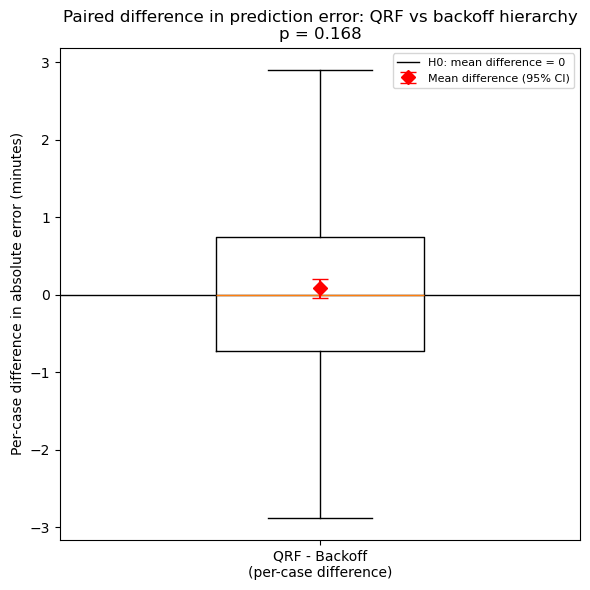

In [177]:
diff_mean = diff.mean()
diff_sem = stats.sem(diff)
diff_ci = stats.t.interval(0.95, len(diff) - 1, loc=diff_mean, scale=diff_sem)
diff_err = diff_mean - diff_ci[0]

fig, ax = plt.subplots(figsize=(6, 6))
ax.boxplot(diff.values, tick_labels=["QRF - Backoff\n(per-case difference)"], widths=0.4, showfliers=False)
ax.axhline(0, color="black", linestyle="-", linewidth=1, label="H0: mean difference = 0")
ax.errorbar([1], [diff_mean], yerr=[[diff_err], [diff_err]], fmt="D", color="red",
            capsize=6, markersize=7, zorder=5, label="Mean difference (95% CI)")
ax.set_ylabel("Per-case difference in absolute error (minutes)")
ax.set_title(f"Paired difference in prediction error: QRF vs backoff hierarchy\n{format_p_value(t_p)}")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig("notebooks/figures/ml_vs_backoff_paired_diff.png", dpi=150, bbox_inches="tight")
plt.show()

### Prediction agreement

Checks how closely the two methods' predictions track each other
directly, independent of either method's accuracy against the actual
outcome: a high R² here would mean the two methods are converging on
similar predictions even though they were fitted independently, using
only predicted p75 duration (regardless of which was closer to the
truth).

Pearson r between backoff and QRF predictions: 0.9957 (R^2 = 0.9913)


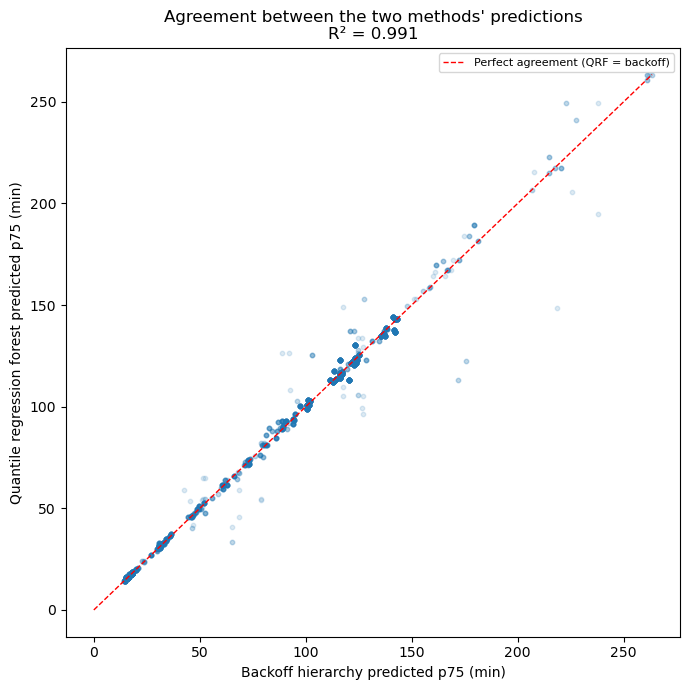

In [176]:
# Agreement between the two methods' raw predictions (not their error
# against ground truth, which the previous cell already covers): if
# the QRF were learning meaningfully different structure than the
# backoff hierarchy, the two methods' individual predictions would
# diverge even if their aggregate accuracy happened to be similar.
# They don't - this scatter and the R^2 below test that directly on
# the same matched cross-validation folds used throughout this
# comparison.
pred_r, pred_p = stats.pearsonr(ml_comparison["backoff_predicted_p75_min"], ml_comparison["ml_predicted_p75_min"])
print(f"Pearson r between backoff and QRF predictions: {pred_r:.4f} (R^2 = {pred_r**2:.4f})")

sample = ml_comparison.sample(min(3000, len(ml_comparison)), random_state=1)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(sample["backoff_predicted_p75_min"], sample["ml_predicted_p75_min"], alpha=0.15, s=10)
lims = [0, max(sample["backoff_predicted_p75_min"].max(), sample["ml_predicted_p75_min"].max())]
ax.plot(lims, lims, color="red", linestyle="--", linewidth=1, label="Perfect agreement (QRF = backoff)")
ax.set_xlabel("Backoff hierarchy predicted p75 (min)")
ax.set_ylabel("Quantile regression forest predicted p75 (min)")
ax.set_title(f"Agreement between the two methods' predictions\nR² = {pred_r**2:.3f}")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("notebooks/figures/ml_vs_backoff_prediction_agreement.png", dpi=150, bbox_inches="tight")
plt.show()
